# 07 — Neural forecasting models

## Purpose

We consolidate the completed **LSTM, GRU, bidirectional LSTM (BiLSTM) and temporal convolutional network (TCN)** development experiments. Each network forecasts SOLETE photovoltaic power using the F0–F4 feature families, 15/30/60-minute horizons and the same three chronological folds as the classical models.

The notebook documents sequence construction, training-only scaling, architecture and epoch-selection choices, verifies the completed neural training checkpoints, and compares F0–F4 and matched F3–F4 results.

## 1. Neural data representation and evaluation

Each neural candidate receives two input branches:

- **Historical sequence:** 13 consecutive 5-minute rows of the nine measured PV/meteorological variables, ending at forecast issue time.
- **Auxiliary features:** the previous-day PV lag and the appropriate future-known Gregorian, solar, continuous lunar and Panchang variables, attached at forecast-valid time.

| Family | Total predictors | Auxiliary features | Historical sequence |
|---|---:|---:|---|
| F0 | 118 | 1 | 13 × 9 |
| F1 | 133 | 16 | 13 × 9 |
| F2 | 138 | 21 | 13 × 9 |
| F3 | 147 | 30 | 13 × 9 |
| F4 | 244 | 127 | 13 × 9 |

All architectures use the same three expanding development folds and a 60-minute availability gap. Data-dependent transformations are fitted on training data only. The terminal SOLETE period is excluded from the development training records.

In [1]:
from pathlib import Path
from itertools import product
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next((folder.resolve() for folder in (Path.cwd(), *Path.cwd().parents)
                     if (folder / 'src' / 'neural_models.py').is_file()
                     and (folder / 'results' / 'development_only').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook from inside the SOLETE project.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))

from src.forecasting_protocol import EXPECTED_CV_COUNTS_BY_HORIZON, MODEL_AVAILABILITY_GAP
from src.revised_neural_cv import FAMILY_DIMENSIONS, AUXILIARY_DIMENSIONS, SEQUENCE_LENGTH, CHANNEL_NAMES
from src.revised_neural_training import (
    INNER_VALIDATION_FRACTION, INNER_LABEL_GAP_MINUTES,
    MAX_SELECTION_EPOCHS, EARLY_STOPPING_PATIENCE,
)
from src.revised_neural_campaign import campaign_source_sha256 as neural_v1_sha
from src.revised_neural_campaign_v2 import campaign_source_sha256 as neural_v2_sha
from src.revised_neural_batch import _audit_prior_source
from src.revised_neural_batch_v2 import _audit_v2, read_mixed_progress
from src.revised_recurrent_extension import read_progress as read_recurrent_progress

ARCHIVE = (PROJECT_ROOT/'results'/'development_only').resolve()
HORIZONS = (15,30,60)
FAMILIES = ('F0','F1','F2','F3','F4')
MODELS = ('LSTM','TCN','GRU','BiLSTM')
assert SEQUENCE_LENGTH == 13 and len(CHANNEL_NAMES) == 9
assert FAMILY_DIMENSIONS == {'F0':118,'F1':133,'F2':138,'F3':147,'F4':244}
assert AUXILIARY_DIMENSIONS == {'F0':1,'F1':16,'F2':21,'F3':30,'F4':127}
assert MODEL_AVAILABILITY_GAP == pd.Timedelta(minutes=60)
display(pd.DataFrame([{'feature_family':family,'total_features':FAMILY_DIMENSIONS[family],
                       'sequence_shape':f'13 × {len(CHANNEL_NAMES)}',
                       'auxiliary_features':AUXILIARY_DIMENSIONS[family]} for family in FAMILIES]))


,feature_family,total_features,sequence_shape,auxiliary_features
0,F0,118,13 × 9,1
1,F1,133,13 × 9,16
2,F2,138,13 × 9,21
3,F3,147,13 × 9,30
4,F4,244,13 × 9,127


## 2. Architecture and training procedure

Each candidate uses a recurrent (LSTM, GRU, BiLSTM) or temporal-convolutional sequence branch and an auxiliary-feature branch. The branches are fused into a final PV-power regressor.

The neural training follows nested time-respecting selection **inside each outer development fold**:

1. Reserve the latest 10% of eligible outer-training observations for inner chronological epoch selection, with a 60-minute embargo.
2. Fit input and target scalers on the corresponding training rows. Keep categorical indicators binary.
3. Fit the network for up to 80 inner-selection epochs; choose its best epoch using inner-validation loss and the frozen early-stopping rule.
4. Reinitialize and refit the candidate on the entire eligible outer training fold for the chosen epoch count.
5. Predict the outer fold and invert the target scaling before computing MAE/RMSE in kW.

Every architecture has four frozen candidate configurations. The V1 F0 checkpoints and V2 F1–F4 checkpoints use distinct documented scaling policies; the latter sets a training-constant `valid_utc_year` standard deviation to one. The neural checkpoints record both inner-selected epoch counts and outer-fold scores.

In [2]:
training_protocol = pd.DataFrame([
    ('inner validation fraction',INNER_VALIDATION_FRACTION),
    ('inner label embargo minutes',INNER_LABEL_GAP_MINUTES),
    ('maximum epoch-selection epochs',MAX_SELECTION_EPOCHS),
    ('early stopping patience',EARLY_STOPPING_PATIENCE),
    ('outer folds',3),
    ('configurations per architecture',4),
    ('models',len(MODELS)),
],columns=['setting','value'])
assert INNER_VALIDATION_FRACTION == 0.10
assert INNER_LABEL_GAP_MINUTES == 60
assert MAX_SELECTION_EPOCHS == 80
assert EARLY_STOPPING_PATIENCE == 8
display(training_protocol)
print('Completed neural candidate-fold evaluations:',4*3*5*4*3)


,setting,value
0,inner validation fraction,0.1
1,inner label embargo minutes,60.0
2,maximum epoch-selection epochs,80.0
3,early stopping patience,8.0
4,outer folds,3.0
5,configurations per architecture,4.0
6,models,4.0


Completed neural candidate-fold evaluations: 720


## 3. Validate the original neural checkpoints

The completed campaign uses the source-fingerprinted F0 archive and a revised F1–F4 archive for LSTM and TCN. The GRU and BiLSTM extension has corresponding source-verified archives. We read the existing training records and verify complete experiment coverage.

In [3]:
v1 = ARCHIVE/'revised_neural_cv_v1'
v2 = ARCHIVE/'revised_neural_cv_v2_year_std1'
assert _audit_prior_source(v1,source_sha256=neural_v1_sha(PROJECT_ROOT)) == 72
assert _audit_v2(v2,neural_v2_sha(PROJECT_ROOT)) == 288
original_neural = read_mixed_progress(v1,v2)
extended_neural = read_recurrent_progress(PROJECT_ROOT)
assert len(original_neural) == 360
assert len(extended_neural) == 360
assert set(original_neural['model']) == {'LSTM','TCN'}
assert set(extended_neural['model']) == {'GRU','BiLSTM'}
print('LSTM/TCN checkpoints:',len(original_neural))
print('GRU/BiLSTM checkpoints:',len(extended_neural))


LSTM/TCN checkpoints: 360
GRU/BiLSTM checkpoints: 360


## 4. Verify training provenance and sample alignment

For all 720 model fits we check the recorded model, configuration, feature family, fold, exact training/validation row counts, measured errors and input-data identity. The data hashes must match across all four architectures for the same horizon, feature family and fold.

In [4]:
def development_file(relative_path):
    file=(ARCHIVE/relative_path).resolve()
    assert file.is_relative_to(ARCHIVE)
    if not file.is_file():
        raise FileNotFoundError(file)
    return file

records=[]
for campaign in (original_neural,extended_neural):
    for row in campaign.itertuples(index=False):
        if row.model in ('LSTM','TCN'):
            folder = ('revised_neural_cv_v1' if row.feature_family == 'F0'
                      else 'revised_neural_cv_v2_year_std1')
        else:
            folder = ('revised_recurrent_extension_v1_F0' if row.feature_family == 'F0'
                      else 'revised_recurrent_extension_v2_year_std1')
        filename=(f'{row.model.lower()}_c{row.config_index+1}_'
                  f'h{row.horizon_minutes}_{row.feature_family}_fold{row.fold}.json')
        item=json.loads(development_file(f'{folder}/{filename}').read_text())
        ident,rec=item['identity'],item['record']
        assert (ident['model'],ident['horizon_minutes'],ident['feature_family'],
                ident['config_index'],ident['outer_fold']) == (
                    row.model,row.horizon_minutes,row.feature_family,row.config_index,row.fold)
        expected_train,expected_val=EXPECTED_CV_COUNTS_BY_HORIZON[row.horizon_minutes][row.fold-1]
        assert (ident['outer_train_rows'],ident['outer_validation_rows']) == (expected_train,expected_val)
        assert np.isclose(rec['validation_mae_kw'],row.validation_mae_kw,rtol=0,atol=1e-12)
        assert np.isclose(rec['validation_rmse_kw'],row.validation_rmse_kw,rtol=0,atol=1e-12)
        records.append({
            'model':row.model,'horizon_minutes':int(row.horizon_minutes),
            'feature_family':row.feature_family,'config_index':int(row.config_index),
            'candidate_id':row.candidate_id,
            'configuration_json':json.dumps(ident['configuration'],sort_keys=True),
            'fold':int(row.fold),'train_rows':int(expected_train),
            'validation_rows':int(expected_val),
            'validation_mae_kw':float(row.validation_mae_kw),
            'validation_rmse_kw':float(row.validation_rmse_kw),
            'best_epoch':int(rec['best_epoch']),
            'trainable_parameters':int(rec['trainable_parameters']),
            'data_sha256':ident['data_sha256'],
            'scaling_policy':ident.get('scaling_policy','F0 archived V1'),
        })
neural_cv=pd.DataFrame(records)
assert len(neural_cv)==720

key=['model','horizon_minutes','feature_family','config_index','fold']
expected_keys=set(product(MODELS,HORIZONS,FAMILIES,range(4),(1,2,3)))
assert set(neural_cv[key].itertuples(index=False,name=None))==expected_keys
assert not neural_cv.duplicated(key).any()
assert (neural_cv.groupby(key[:-1])['fold'].nunique()==3).all()
assert np.isfinite(neural_cv[['validation_mae_kw','validation_rmse_kw']].to_numpy()).all()
assert (neural_cv['validation_rmse_kw']+1e-8 >= neural_cv['validation_mae_kw']).all()
assert neural_cv['best_epoch'].gt(0).all() and neural_cv['trainable_parameters'].gt(0).all()
reference=(neural_cv.query("model == 'LSTM' and config_index == 0")
            .set_index(['horizon_minutes','feature_family','fold'])['data_sha256'])
assert len(reference)==45
for row in neural_cv.itertuples(index=False):
    assert row.data_sha256 == reference.loc[(row.horizon_minutes,row.feature_family,row.fold)]
print('NEURAL TRAINING CHECKPOINTS: 720/720 VALIDATED')
display(neural_cv.groupby('model',as_index=False).agg(
    fold_fits=('fold','size'),median_best_epoch=('best_epoch','median'),
    median_parameters=('trainable_parameters','median')))


NEURAL TRAINING CHECKPOINTS: 720/720 VALIDATED


,model,fold_fits,median_best_epoch,median_parameters
0,BiLSTM,180,7.0,42721.0
1,GRU,180,4.0,17185.0
2,LSTM,180,6.0,21729.0
3,TCN,180,2.0,57825.0


## 5. Training stability and selected epochs

Different architectures and configurations can select different epoch counts even with the same outer folds. We summarize the chosen epochs and fitted parameter counts from the saved training records.

In [5]:
training_summary=(neural_cv.groupby(['model','horizon_minutes'],as_index=False).agg(
    completed_fits=('fold','size'),
    median_best_epoch=('best_epoch','median'),
    min_best_epoch=('best_epoch','min'),max_best_epoch=('best_epoch','max'),
    median_trainable_parameters=('trainable_parameters','median')))
assert len(training_summary)==4*3
assert training_summary['completed_fits'].eq(5*4*3).all()
display(training_summary)


,model,horizon_minutes,completed_fits,median_best_epoch,min_best_epoch,max_best_epoch,median_trainable_parameters
0,BiLSTM,15,60,6.0,1,25,42721.0
1,BiLSTM,30,60,9.0,1,30,42721.0
2,BiLSTM,60,60,7.0,1,26,42721.0
3,GRU,15,60,3.5,1,14,17185.0
4,GRU,30,60,4.0,1,12,17185.0
5,GRU,60,60,4.0,1,17,17185.0
6,LSTM,15,60,6.5,1,22,21729.0
7,LSTM,30,60,5.0,1,20,21729.0
8,LSTM,60,60,5.0,1,22,21729.0
9,TCN,15,60,2.0,1,42,57825.0


## 6. Compare F0–F4 across neural architectures

We rank candidate configurations using the **arithmetic mean of the three outer-fold MAEs**. The table presents the best fixed candidate per feature family. This comparison shows the full progression from observational history to Panchang categories for all four neural models.

In [6]:
candidate_keys=['model','horizon_minutes','feature_family','config_index',
                'candidate_id','configuration_json']
neural_candidates=(neural_cv.groupby(candidate_keys,as_index=False).agg(
    cv_mae_kw=('validation_mae_kw','mean'),cv_rmse_kw=('validation_rmse_kw','mean'),
    fold_mae_std_kw=('validation_mae_kw','std'),folds=('fold','nunique'),
    median_best_epoch=('best_epoch','median')))
assert len(neural_candidates)==4*3*5*4==240
assert neural_candidates['folds'].eq(3).all()
neural_candidates=neural_candidates.sort_values(
    ['model','horizon_minutes','feature_family','cv_mae_kw','config_index'],kind='stable')
neural_winners=neural_candidates.drop_duplicates(
    ['model','horizon_minutes','feature_family']).reset_index(drop=True)
assert len(neural_winners)==4*3*5==60
neural_progression=neural_winners.pivot(index=['model','horizon_minutes'],
    columns='feature_family',values='cv_mae_kw').reindex(columns=list(FAMILIES))
print('Best neural candidate per feature family — mean development-fold MAE (kW):')
display(neural_progression.round(6))


Best neural candidate per feature family — mean development-fold MAE (kW):


feature_family                F0        F1        F2        F3        F4
model  horizon_minutes                                                  
BiLSTM 15               0.200565  0.263973  0.227600  0.230290  0.218282
       30               0.242536  0.301893  0.285513  0.268845  0.282405
       60               0.322029  0.326201  0.355773  0.308861  0.337557
GRU    15               0.205875  0.208510  0.246920  0.224423  0.239570
       30               0.261179  0.273950  0.318524  0.289256  0.290742
       60               0.341018  0.356374  0.374408  0.405096  0.394781
LSTM   15               0.206821  0.232145  0.235256  0.270439  0.240270
       30               0.260960  0.281023  0.341875  0.306357  0.304457
       60               0.346670  0.398943  0.374726  0.378638  0.379059
TCN    15               0.604037  1.167045  0.589501  0.659632  0.327693
       30               0.472601  0.527562  0.520028  0.619224  0.539749
       60               0.536669  0.542134  0.501114  0.641698  0.595898

## 7. Matched neural F3–F4 comparison

We pair each F3 model with its F4 counterpart at the **same architecture, horizon and configuration index**. The signed error reduction is `MAE(F3) − MAE(F4)`; positive favors F4. Separately tuned family-best results are shown as a descriptive comparison.

In [7]:
paired_keys=['model','horizon_minutes','config_index']
f3=neural_candidates.query("feature_family == 'F3'")
f4=neural_candidates.query("feature_family == 'F4'")
neural_pairs=f3[paired_keys+['cv_mae_kw']].merge(
    f4[paired_keys+['cv_mae_kw']],on=paired_keys,suffixes=('_F3','_F4'),validate='one_to_one')
neural_pairs['f4_gain_kw']=neural_pairs['cv_mae_kw_F3']-neural_pairs['cv_mae_kw_F4']
assert len(neural_pairs)==4*3*4==48
neural_matched=(neural_pairs.groupby(['model','horizon_minutes'],as_index=False).agg(
    matched_configs=('config_index','size'),
    mean_gain_kw=('f4_gain_kw','mean'),
    configs_favoring_f4=('f4_gain_kw',lambda x:int((x>0).sum()))))
print('Matched F3 to F4 — positive improvement favors F4:')
display(neural_matched.round(6))
w3=neural_winners.query("feature_family == 'F3'")[['model','horizon_minutes','cv_mae_kw']]
w4=neural_winners.query("feature_family == 'F4'")[['model','horizon_minutes','cv_mae_kw']]
neural_tuned=w3.merge(w4,on=['model','horizon_minutes'],suffixes=('_F3','_F4'),validate='one_to_one')
neural_tuned['f4_gain_kw']=neural_tuned['cv_mae_kw_F3']-neural_tuned['cv_mae_kw_F4']
print('Separately tuned family-best F3–F4:')
display(neural_tuned.round(6))


Matched F3 to F4 — positive improvement favors F4:


,model,horizon_minutes,matched_configs,mean_gain_kw,configs_favoring_f4
0,BiLSTM,15,4,0.023255,3
1,BiLSTM,30,4,-0.034180,0
2,BiLSTM,60,4,-0.022631,0
3,GRU,15,4,-0.013106,2
4,GRU,30,4,-0.009305,1
5,GRU,60,4,0.011311,3
6,LSTM,15,4,0.042648,4
7,LSTM,30,4,-0.000387,2
8,LSTM,60,4,0.009550,2
9,TCN,15,4,0.667829,3


Separately tuned family-best F3–F4:


,model,horizon_minutes,cv_mae_kw_F3,cv_mae_kw_F4,f4_gain_kw
0,BiLSTM,15,0.230290,0.218282,0.012008
1,BiLSTM,30,0.268845,0.282405,-0.013560
2,BiLSTM,60,0.308861,0.337557,-0.028696
3,GRU,15,0.224423,0.239570,-0.015146
4,GRU,30,0.289256,0.290742,-0.001486
5,GRU,60,0.405096,0.394781,0.010315
6,LSTM,15,0.270439,0.240270,0.030169
7,LSTM,30,0.306357,0.304457,0.001900
8,LSTM,60,0.378638,0.379059,-0.000421
9,TCN,15,0.659632,0.327693,0.331939


## 8. Visualize neural feature-family performance

The line charts show the full F0–F4 development accuracy progression for the four architectures. The matched-configuration effect estimates remain our controlled comparison of categorical Panchang representation.

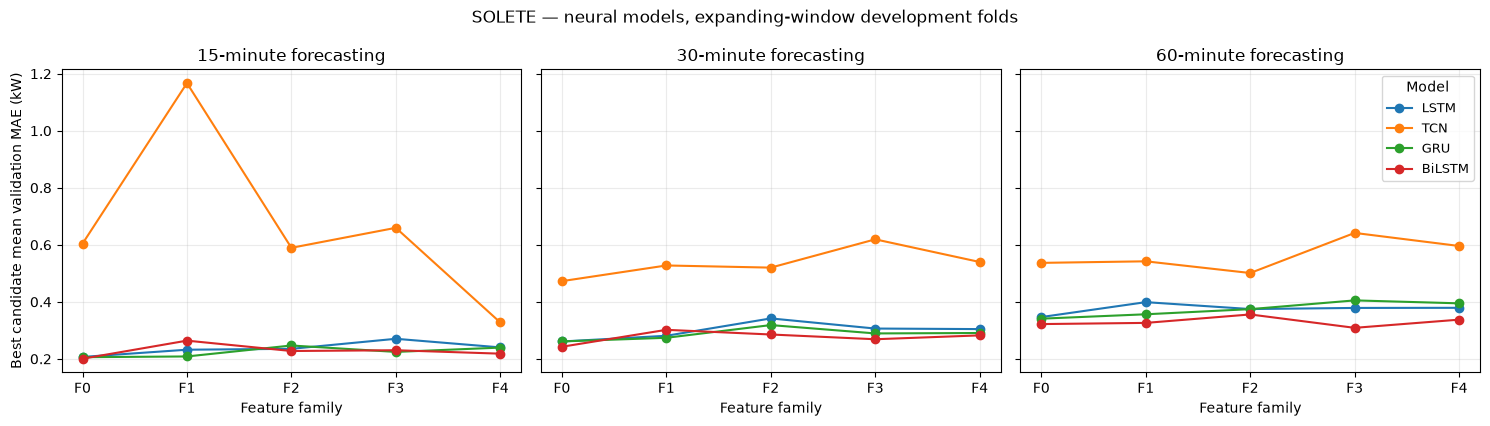

In [8]:
fig,axes=plt.subplots(1,3,figsize=(15,4.3),sharey=True)
for ax,horizon in zip(axes,HORIZONS):
    for model in MODELS:
        ax.plot(FAMILIES,
                neural_progression.loc[(model,horizon),list(FAMILIES)].to_numpy(dtype=float),
                label=model,marker='o')
    ax.set_title(f'{horizon}-minute forecasting')
    ax.set_xlabel('Feature family')
    ax.grid(alpha=.25)
axes[0].set_ylabel('Best candidate mean validation MAE (kW)')
axes[-1].legend(title='Model',fontsize=9)
fig.suptitle('SOLETE — neural models, expanding-window development folds')
fig.tight_layout()
plt.show()


## 9. Preserve neural training results

The consolidated tables retain all 720 checkpointed fit scores, candidate rankings, selected configurations, training-epoch summaries and matched F3–F4 comparisons. The next notebook will combine them with the classical models using the same development folds.

In [9]:
OUTPUT_DIR=PROJECT_ROOT/'results'/'model_architectures'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
artifacts={
    'neural_fold_scores.csv':neural_cv,
    'neural_candidate_rankings.csv':neural_candidates,
    'neural_family_winners.csv':neural_winners,
    'neural_training_summary.csv':training_summary,
    'neural_matched_f3_f4.csv':neural_pairs,
    'neural_tuned_f3_f4.csv':neural_tuned,
}
for name,frame in artifacts.items():
    filename=OUTPUT_DIR/name
    frame.to_csv(filename,index=False,float_format='%.12g')
    assert len(pd.read_csv(filename))==len(frame)
    print(name,':',len(frame),'rows')
assert len(neural_cv)==720 and len(neural_candidates)==240
assert len(neural_winners)==60 and len(neural_pairs)==48
print('NOTEBOOK 13: NEURAL MODEL ARCHIVE CHECKS PASSED')


neural_fold_scores.csv : 720 rows
neural_candidate_rankings.csv : 240 rows
neural_family_winners.csv : 60 rows
neural_training_summary.csv : 12 rows
neural_matched_f3_f4.csv : 48 rows
neural_tuned_f3_f4.csv : 12 rows
NOTEBOOK 13: NEURAL MODEL ARCHIVE CHECKS PASSED


## What we learned

The revised neural development campaign includes **720 completed candidate-fold evaluations** across LSTM, TCN, GRU and BiLSTM, including the F0–F4 hierarchy. All four architectures share the same outer training and validation populations, and the saved checkpoints document both selected epochs and prediction errors.

The F0–F4 comparison describes feature-family gains for each neural architecture. The matched F3–F4 analysis tests the categorical representation under the same neural configuration. The next step combines these results with the 945 classical evaluations.